In [1]:
%matplotlib inline
import itertools
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
from scipy.optimize import least_squares
import convert_data as cd

SEED = 2025                      # the only seed in this notebook (every bootstrap)
NBOOT = 300                      # bootstrap replicates
t_start = time.perf_counter()
m = 6
labels = ['v', 'P', 'T0', 'Y', 'E', 'rho']

# Risk-Based Design Optimization for Powder Bed Fusion: Maximum Residual Stress after One Electron-Beam Scan

__Yulin Guo__, Department of Mechanical and Aerospace Engineering, University of California San Diego, La Jolla, CA, USA

__Boris Kramer__, Department of Mechanical and Aerospace Engineering, University of California San Diego, La Jolla, CA, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes the Abaqus runs that Guo and Kramer [[1]][R1] published with their article. The values are **stored data**: they were produced by the authors' finite element models, which need Abaqus and a heat-source user subroutine that is not published, and they are used here unchanged (`DATA.md`).

### Summary

Guo and Kramer [[1]][R1] simulate the fusing of one 50 µm Ti–6Al–4V powder layer by a single electron-beam scan with sequential thermal and mechanical Abaqus models, and they use the maximum von Mises residual stress $\sigma_{\max}$ after cooling as the limit-state function of a risk-constrained design problem over scanning speed and beam power, with preheating temperature, yield strength, elastic modulus and density uncertain. From the authors' 120 training runs (values only), a global quadratic gives one dominant direction for $\sigma_{\max}$ ($\lambda_1/\lambda_2 = 28.1$, bootstrap median 14.6), made mostly of beam power (+0.920) against scanning speed (−0.342); the same direction comes out of the 63 runs below yield ($|\mathbf w_1\cdot\mathbf w_1| = 0.966$) and of a quadratic capped at the yield strength (0.989; LOO $R^2 = 0.956$ against 0.809 for the plain quadratic), its small $(T_0, Y, E, \rho)$ part is confirmed by the unseen validation runs ($|\cos| = 0.984$ and 0.996), and a degree-4 polynomial in the single active variable predicts $\sigma_{\max}$ with leave-one-out $R^2 = 0.9214$. The sufficient summary plot shows why the structure is one-dimensional but kinked: 57 of the 120 runs reach the yield strength, and the active variable separates them (every run with $y_1 > 0.440$ has yielded and none with $y_1 < -0.177$ has) and tracks the temperature at the end of the scan track (correlation 0.958), while the paper's validation superquantiles (Table 4) are not reproduced from the stored runs by any estimator tried.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs normalized to $[-1, 1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$ [[2]][R2], [[3]][R3]. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, and a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows its main trend. Without gradients, $\nabla f$ is replaced by the gradient of a model fitted to the values; here a global least-squares quadratic $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$, for which $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \mathbf I/3$ on $[-1, 1]^m$. A short introduction is in Constantine's book [[2]][R2].

### The model

**Process** (Sects. 3.1–3.5 of [[1]][R1]). An electron beam scans once along the length (the $x$-direction) of a $2 \times 1.5 \times 0.65$ mm part: a 50 µm layer of Ti–6Al–4V powder on 0.6 mm of bulk material from earlier scans. The thermal model is

$$\rho\, C_p(T)\,\frac{\partial T}{\partial t} = \nabla\cdot\big(\kappa(T)\nabla T\big) + Q_e, \qquad C_p(T) = a_0 + a_1T + a_2T^2,\quad \kappa(T) = b_0 + b_1T + b_2T^2,$$

with the Gaussian beam flux

$$Q_e(x, y, z, t) = \frac{2AP}{\pi r^2 z_0}\exp\!\left(-\frac{2\big((x - vt)^2 + y^2\big)}{r^2}\right)\frac15\left[-3\left(\frac{z}{z_0}\right)^2 - 2\frac{z}{z_0} + 5\right]$$

(Eqs. 2–3; $P$ beam power, $v$ scanning speed, $r$ spot radius, $z_0$ penetration depth, $A = 0.203$ absorptivity), radiation from the top surface to a chamber at $T_c = 650$ °C with emissivity 0.35, and latent heat 365,000 J/kg between the solidus (1605 °C) and liquidus (1650 °C). The temperature history drives a quasi-static mechanical model $\nabla\cdot\boldsymbol\sigma + \mathbf f = 0$, $\boldsymbol\sigma^e = \mathbb C\boldsymbol\epsilon^e$, $\boldsymbol\epsilon = \boldsymbol\epsilon^e + \boldsymbol\epsilon^p + \boldsymbol\epsilon^t$, elastic–perfectly plastic, with Poisson's ratio 0.41 and thermal expansion $10^{-5}$ (Eqs. 4–5, Sect. 5.1). The coupling is one-way. The mesh has 13,200 nodes and 10,752 elements (DC3D8 thermal, C3D8R mechanical), refined in the powder. The Abaqus models have four steps (preheating, laying powder, moving heat, cooling).

**Quantity of interest** (Sects. 3.5, 4.2.4). $\sigma_{\max}$ (MPa) is the maximum von Mises stress at the end of the cooling step over the 448 integration points of the $x_c$–$z_c$ plane through the part centroid (a $32 \times 14$ grid, Fig. 2b). The authors store the 448 values of every run, so the notebook computes $\sigma_{\max}$ exactly, as the maximum of each row. The paper's second output, the peak top-surface temperature $T_{\max}$ of the moving-heat step, cannot be computed: the published temperature files hold only cooling-step histories (`DATA.md`). Their first frame, the end of the moving-heat step, gives lower bounds on the peak temperature at five points, which are used below for context.

**Inputs** (m = 6, all independent and uniform; Sect. 5.1 and Table 1, p. 12; the paper takes the distributions from Vohra et al. [[4]][R4]). The design variables are $v$ and $P$; the uncertain variables are the preheating temperature $T_0$, yield strength $Y$, elastic modulus $E$ and bulk density $\rho$. The six coefficients of $C_p$ and $\kappa$ are held at $a_0 = 540$, $a_1 = 0.43$, $a_2 = -3.2\times10^{-5}$, $b_0 = 7.2$, $b_1 = 0.011$, $b_2 = 1.4\times10^{-6}$ (Sect. 5.1). **The stored samples of $E$ and $\rho$ do not follow Table 1.** Table 1 gives $E \in [100, 120]$ GPa and $\rho \in [3870, 4730]$ kg/m³ (4300 ± 10 %); the samples fill $[99, 121]$ GPa and $[3985.2, 4870.8]$ kg/m³, that is 110 ± 10 % and the bulk density 4428 ± 10 % (Sect. 5.1). With these bounds every input column of the training runs is a Latin hypercube with exactly one point in each of the 120 strata; with Table 1's bounds 11 values of $E$ and 19 of $\rho$ fall outside (checked below). The notebook therefore uses the bounds the samples were drawn from. The table is built from `convert_data.py`.

In [2]:
print(f"{'j':>2s}  {'name':4s} {'units':7s} {'lower':>8s} {'upper':>8s} {'Table 1 lower':>14s} {'Table 1 upper':>14s}")
for j, (n, u) in enumerate(zip(cd.NAMES, cd.UNITS)):
    print(f'{j + 1:2d}  {n:4s} {u:7s} {cd.LOWER[j]:8.1f} {cd.UPPER[j]:8.1f} {cd.TABLE1_LOWER[j]:14.1f} {cd.TABLE1_UPPER[j]:14.1f}')

 j  name units      lower    upper  Table 1 lower  Table 1 upper
 1  v    mm/s       100.0   1000.0          100.0         1000.0
 2  P    W           20.0    200.0           20.0          200.0
 3  T0   degC       585.0    715.0          585.0          715.0
 4  Y    MPa        742.5    907.5          742.5          907.5
 5  E    GPa         99.0    121.0          100.0          120.0
 6  rho  kg/m^3    3985.2   4870.8         3870.0         4730.0


### Load data

`convert_data.py` copied four files of the authors' zip archive into CSV files with two `#` header lines, keeping every number's original text (see `DATA.md`). The input files hold the six varied inputs and the six held coefficients; the stress files hold the 448 von Mises stresses per run. From the cooling-step temperature histories it kept only the first frame (the temperature at five points at the end of the moving-heat step), as two small files; file $i$ of the source is row $i - 1$ (checked below). No row is dropped.

In [3]:
Xtr = np.loadtxt('pbf_training_inputs.csv', delimiter=',')      # 120 x 12: v, P, T0, Y, E, rho, a0..b2
Str = np.loadtxt('pbf_training_stress.csv', delimiter=',')      # 120 x 448 von Mises stress (MPa)
Xva = np.loadtxt('pbf_validation_inputs.csv', delimiter=',')    # 100 x 12
Sva = np.loadtxt('pbf_validation_stress.csv', delimiter=',')    # 100 x 448
X, Xv = Xtr[:, :m], Xva[:, :m]                                  # the six varied inputs, physical units
Ttr = np.loadtxt('pbf_training_cooling_start_T.csv', delimiter=',')    # 120 x 5 temperature (degC) at t = 0 of cooling
Tva = np.loadtxt('pbf_validation_cooling_start_T.csv', delimiter=',')  # 100 x 5
smax, smax_v = Str.max(axis=1), Sva.max(axis=1)                 # QoI: maximum over the 448 points (MPa)
print('training:  X', X.shape, ' stress field', Str.shape, ' sigma_max', smax.shape)
print('validation: X', Xv.shape, ' stress field', Sva.shape, ' sigma_max', smax_v.shape)
print('cooling-start temperatures at 5 points: training', Ttr.shape, ' validation', Tva.shape)

training:  X (120, 6)  stress field (120, 448)  sigma_max (120,)
validation: X (100, 6)  stress field (100, 448)  sigma_max (100,)
cooling-start temperatures at 5 points: training (120, 5)  validation (100, 5)


**Checks of the stored data.** The cell checks the held coefficients, the sampling design (points outside the bounds, and the largest number of points in a stratum of width $1/M$; a Latin hypercube has one), whether the design is symmetric (the paper says "optimal symmetric Latin hypercube", p. 12), how many runs reach the yield strength, and the SVD truncation error $\mathsf{err}_S(k)$ of the paper's Eq. (20).

In [4]:
lo, hi = np.array(cd.LOWER), np.array(cd.UPPER)
t1lo, t1hi = np.array(cd.TABLE1_LOWER), np.array(cd.TABLE1_UPPER)
print('held coefficients a0, a1, a2, b0, b1, b2 (constant in all 220 runs):',
      np.unique(np.vstack([Xtr[:, m:], Xva[:, m:]]), axis=0).ravel())


def strata(Xs, lo_, hi_):
    """Points outside [lo, hi] and the largest count in a stratum of width 1/M, per column."""
    U = (Xs - lo_) / (hi_ - lo_)
    M = len(Xs)
    out = ((U < 0) | (U >= 1)).sum(0)
    K = np.clip(np.floor(U * M).astype(int), 0, M - 1)
    most = np.array([np.bincount(K[:, j], minlength=M).max() for j in range(Xs.shape[1])])
    return out, most, K


out, most, K = strata(X, lo, hi)
out1, most1, _ = strata(X, t1lo, t1hi)
print('training, bounds of this notebook: points outside', out, '; max per stratum', most)
print('training, bounds of Table 1:       points outside', out1, '; max per stratum', most1)
print(f'training E in [{X[:, 4].min():.3f}, {X[:, 4].max():.3f}] GPa, rho in [{X[:, 5].min():.1f}, {X[:, 5].max():.1f}] kg/m^3')
mirror = sum(tuple(119 - k) in set(map(tuple, K)) for k in K)
print('training runs whose mirror stratum (119 - k in every column) is also occupied:', mirror)
designs = np.unique(Xv[:, :2], axis=0)
for d in designs:
    blk = np.all(Xv[:, :2] == d, axis=1)
    o, mo, _ = strata(Xv[blk, 2:], lo[2:], hi[2:])
    print(f'validation design (v, P) = ({d[0]}, {d[1]}): {blk.sum()} runs; T0, Y, E, rho outside bounds {o}, '
          f'max per stratum of width 1/{blk.sum()} {mo}')

r = smax / X[:, 3]
sat = r >= 0.999
print(f'\nsigma_max: [{smax.min():.2f}, {smax.max():.2f}] MPa, mean {smax.mean():.1f}; smallest stress anywhere {Str.min():.3f} MPa')
print(f'runs with sigma_max >= 0.999 Y (yielded): {sat.sum()} of 120; with sigma_max > Y: {(r > 1).sum()}, '
      f'largest excess {(r.max() - 1):.2e} Y')
print(f'validation: sigma_max >= 0.999 Y in {(smax_v / Xv[:, 3] >= 0.999).sum()} of 100; > Y in {(smax_v > Xv[:, 3]).sum()}')

U_, s_, Vt_ = np.linalg.svd(Str, full_matrices=False)
errS = [np.mean(np.linalg.norm(Str - (U_[:, :k] * s_[:k]) @ Vt_[:k], axis=1) / np.linalg.norm(Str, axis=1))
        for k in range(1, 7)]
print('err_S(k), Eq. (20), k = 1..6:', np.array2string(100 * np.array(errS), precision=2), '%')

held coefficients a0, a1, a2, b0, b1, b2 (constant in all 220 runs): [ 5.4e+02  4.3e-01 -3.2e-05  7.2e+00  1.1e-02  1.4e-06]
training, bounds of this notebook: points outside [0 0 0 0 0 0] ; max per stratum [1 1 1 1 1 1]
training, bounds of Table 1:       points outside [ 0  0  0  0 11 19] ; max per stratum [ 1  1  1  1  7 20]
training E in [99.129, 120.896] GPa, rho in [3989.3, 4866.7] kg/m^3
training runs whose mirror stratum (119 - k in every column) is also occupied: 0
validation design (v, P) = (417.3, 82.97): 50 runs; T0, Y, E, rho outside bounds [0 0 0 0], max per stratum of width 1/50 [1 1 1 1]
validation design (v, P) = (614.5, 115.8): 50 runs; T0, Y, E, rho outside bounds [0 0 0 0], max per stratum of width 1/50 [1 1 1 1]

sigma_max: [5.27, 899.53] MPa, mean 542.6; smallest stress anywhere 2.436 MPa
runs with sigma_max >= 0.999 Y (yielded): 57 of 120; with sigma_max > Y: 27, largest excess 6.48e-05 Y
validation: sigma_max >= 0.999 Y in 15 of 100; > Y in 4
err_S(k), Eq. (20), 

The six coefficients are the same in all 220 runs and equal Sect. 5.1's values. With the notebook's bounds every training column has one point per stratum, so the design is a Latin hypercube; with Table 1's bounds, 11 values of $E$ and 19 of $\rho$ lie outside and up to 7 and 20 points share a stratum. No training run has its mirror stratum occupied, so the stored design is not symmetric in the usual sense (a run in strata $k$ paired with one in $119 - k$); whether it is "optimal" cannot be checked. At each of the two validation designs, the 50 values of $(T_0, Y, E, \rho)$ form a 50-point Latin hypercube.

$\sigma_{\max}$ ranges from 5.27 to 899.53 MPa (mean 542.6), and no stress in any field is negative (the smallest is 2.436 MPa), as a von Mises stress must be. The model is elastic–perfectly plastic with a temperature-independent yield stress, so $\sigma_{\max}$ cannot exceed $Y$ except by the solver's tolerance: 57 of the 120 training runs reach $0.999\,Y$, and 27 exceed $Y$, by at most $6.48\times10^{-5}\,Y$. These are kept as they are. The truncation errors $\mathsf{err}_S(5) = 10.37\,\%$ and $\mathsf{err}_S(6) = 9.28\,\%$ equal the paper's printed values ("decreases from 10.37 % to 9.28 % when k increases from 5 to 6", p. 14), so these files are the runs behind the paper's surrogates.

### Estimate the active subspace

There are no gradients. With $M = 120$ runs and $m = 6$, a global quadratic in all six inputs has $(m+1)(m+2)/2 = 28$ coefficients, and $M \ge 2 \times 28$, so the notebook uses the library's QPHD estimator, $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ from the least-squares quadratic in normalized inputs, which is the exact average of $\nabla q\,\nabla q^T$ for any input density with mean 0 and covariance $\boldsymbol\Sigma = \mathbf I/3$, the uniform one included. The library warns that QPHD's justification through Stein's lemma holds only for Gaussian inputs; that justification is not used here. Local linear gradients and a global linear fit are cross-checks below. The pairs bootstrap uses 300 replicates, and eigenvector signs are set so that $\sigma_{\max}$ increases along $\mathbf w_1$ and $\mathbf w_2$ (the paper reports no eigenvectors).

In [5]:
space = ac.Uniform(lo, hi, names=labels)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    sub = ac.active_subspace(space=space, X=X, f=smax, estimator='qphd', nboot=NBOOT, bootstrap_vectors=2, rng=SEED)
for w in caught:                                  # shown once, summarized (see the text above and below)
    print('library warning:', str(w.message).split(';')[0])
sub = ac.orient(sub, by='covariance', X=X, f=smax)
lam = sub.eigenvalues
lam_lo, lam_hi = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
quad = ac.fit_surrogate(X=X, f=smax, space=space, subspace=None, kind='poly', degree=2)
r2_in = 1 - np.sum(quad.residuals**2) / np.sum((smax - smax.mean())**2)
print('eigenvalues (MPa^2):', np.array2string(lam, precision=1))
print('95% bootstrap intervals:')
for k in range(m):
    print(f'  lambda_{k + 1}: {lam[k]:10.1f}  [{lam_lo[k]:10.1f}, {lam_hi[k]:10.1f}]')
print(f'lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}; eigenvalue-gap rule: n = {sub.n}')
ratio_b = sub.bootstrap_eigenvalues[:, 0] / sub.bootstrap_eigenvalues[:, 1]
print(f'95% bootstrap interval of lambda1/lambda2: [{np.percentile(ratio_b, 2.5):.1f}, {np.percentile(ratio_b, 97.5):.1f}]')
print(f'global quadratic in all 6 inputs (28 coefficients): R^2 = {r2_in:.4f}, LOO R^2 = {quad.loo_r_squared:.4f}')

library warning: outside the method's assumptions
library warning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1])
eigenvalues (MPa^2): [340979.5  12155.1   6425.6   4111.    2594.7    914.5]
95% bootstrap intervals:
  lambda_1:   340979.5  [  270087.4,   486143.8]
  lambda_2:    12155.1  [    9564.5,    58300.8]
  lambda_3:     6425.6  [    4403.3,    33598.9]
  lambda_4:     4111.0  [    1791.0,    14716.1]
  lambda_5:     2594.7  [     542.8,     8669.7]
  lambda_6:      914.5  [      27.4,     2752.6]
lambda1/lambda2 = 28.1, lambda2/lambda3 = 1.89; eigenvalue-gap rule: n = 1
95% bootstrap interval of lambda1/lambda2: [5.6, 45.8]
global quadratic in all 6 inputs (28 coefficients): R^2 = 0.8912, LOO R^2 = 0.8093


One eigenvalue dominates: $\lambda_1/\lambda_2 = 28.1$ (95 % bootstrap interval $[5.6, 45.8]$), and the eigenvalue-gap rule picks $n = 1$. The next eigenvalues decrease slowly ($\lambda_2/\lambda_3 = 1.89$), and their bootstrap intervals overlap, so beyond the first direction there is no clear structure. The global quadratic itself fits only moderately (in-sample $R^2 = 0.8912$, LOO $R^2 = 0.8093$), because $\sigma_{\max}$ has a kink where it meets the yield strength; the estimated directions describe the quadratic trend of the data, not exact derivatives. Checks of $n = 1$ that take the kink into account follow the cross-checks below.

**Eigenvalues and subspace errors.** Left: eigenvalues with 95 % bootstrap bands; right: the mean bootstrap distance between the estimated and replicate subspaces of dimension $k$.

mean bootstrap subspace distance, k = 1..5: [0.098 0.637 0.829 0.829 0.788]


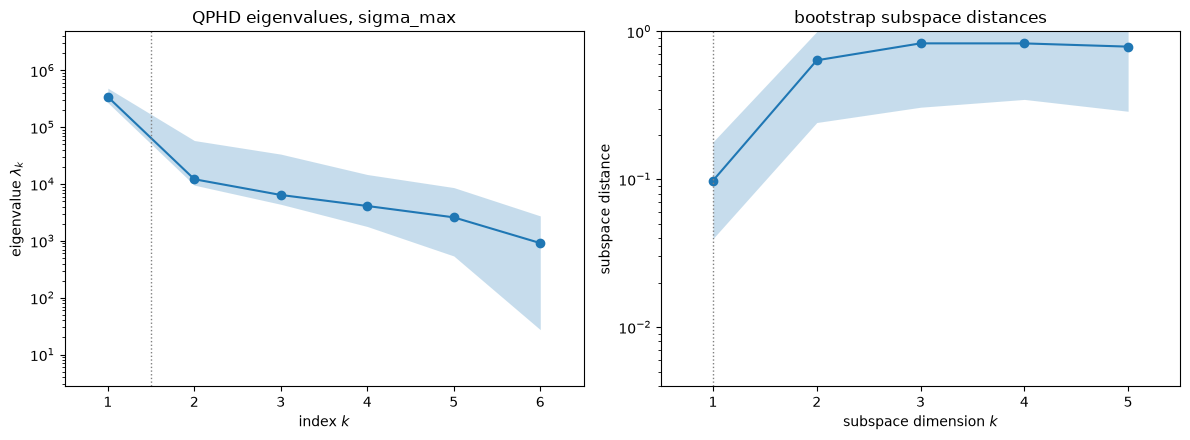

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_eigenvalues(sub, ax=axes[0])
ac.plotting.plot_subspace_errors(sub, ax=axes[1])
axes[0].set_title('QPHD eigenvalues, sigma_max'); axes[1].set_title('bootstrap subspace distances')
fig.tight_layout(); plt.close(fig)
dist = sub.bootstrap_distances.mean(0)
print('mean bootstrap subspace distance, k = 1..5:', np.array2string(dist[:5], precision=3))
fig

The first direction is well determined (mean subspace distance 0.098), and the two-dimensional subspace is not (0.637). The library warns that the replicates of $\mathbf w_2$ are poorly aligned with the estimate, which is what a small second gap predicts.

**Eigenvectors** in normalized inputs, with 95 % bootstrap intervals.

w1: v -0.342 [-0.446, -0.259]  P +0.920 [+0.874, +0.944]  T0 -0.057 [-0.130, +0.019]  Y -0.053 [-0.132, +0.024]  E +0.156 [+0.045, +0.248]  rho -0.080 [-0.159, +0.013]
w2: v +0.722 [-0.176, +0.909]  P +0.229 [-0.144, +0.361]  T0 +0.220 [-0.553, +0.695]  Y -0.599 [-0.904, +0.059]  E +0.045 [-0.702, +0.784]  rho -0.127 [-0.741, +0.514]


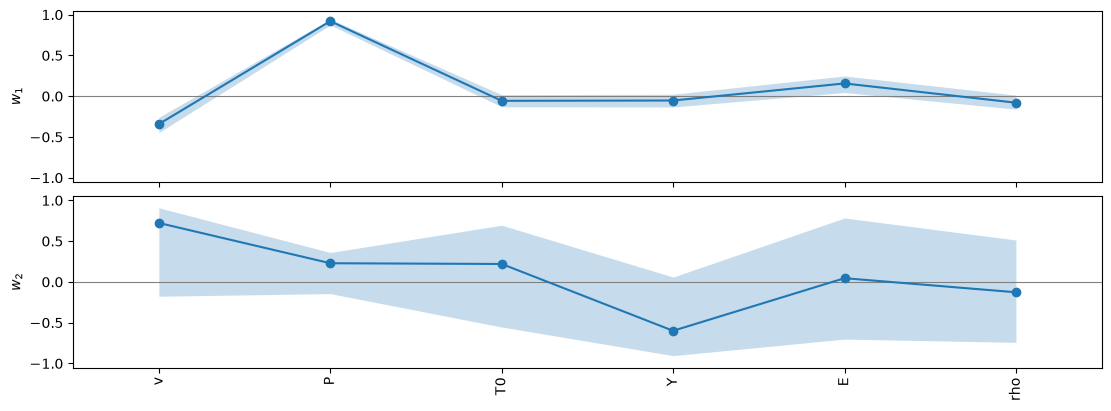

In [7]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile', figsize=(11, 4))
plt.close(fig)
Wb = sub.bootstrap_eigenvectors                       # (B, m, 2), sign-aligned
w_lo, w_hi = np.percentile(Wb, [2.5, 97.5], axis=0)
for i in range(2):
    print(f'w{i + 1}:', '  '.join(f'{l} {sub.W[j, i]:+.3f} [{w_lo[j, i]:+.3f}, {w_hi[j, i]:+.3f}]' for j, l in enumerate(labels)))
fig

$\mathbf w_1$ is beam power (+0.920, interval $[+0.874, +0.944]$) against scanning speed (−0.342, $[-0.446, -0.259]$), with a small elastic-modulus component (+0.156, $[+0.045, +0.248]$); the intervals of $T_0$, $Y$ and $\rho$ contain zero. More power and a slower scan put more energy into the layer, which raises the residual stress. $\mathbf w_2$ (mostly $v$, +0.722, and $Y$, −0.599, in the full-sample estimate) has a 95 % interval containing zero in every component, so it is not interpreted.

**Sufficient summary plots.** Left: $\sigma_{\max}$ against $y_1$; middle: against $(y_1, y_2)$; right: $\sigma_{\max}/Y$ against $y_1$, with the runs that reach $0.999\,Y$ in red.

corr(y1, sigma_max) = 0.888; corr(y1, P/v) = 0.697; corr(y1, log(P/v)) = 0.851
yielded runs: y1 in [-0.177, 1.199]; runs below yield: y1 in [-1.225, 0.440]
runs with y1 > 0.440: 34, all yielded; runs with y1 < -0.177: 51, none yielded


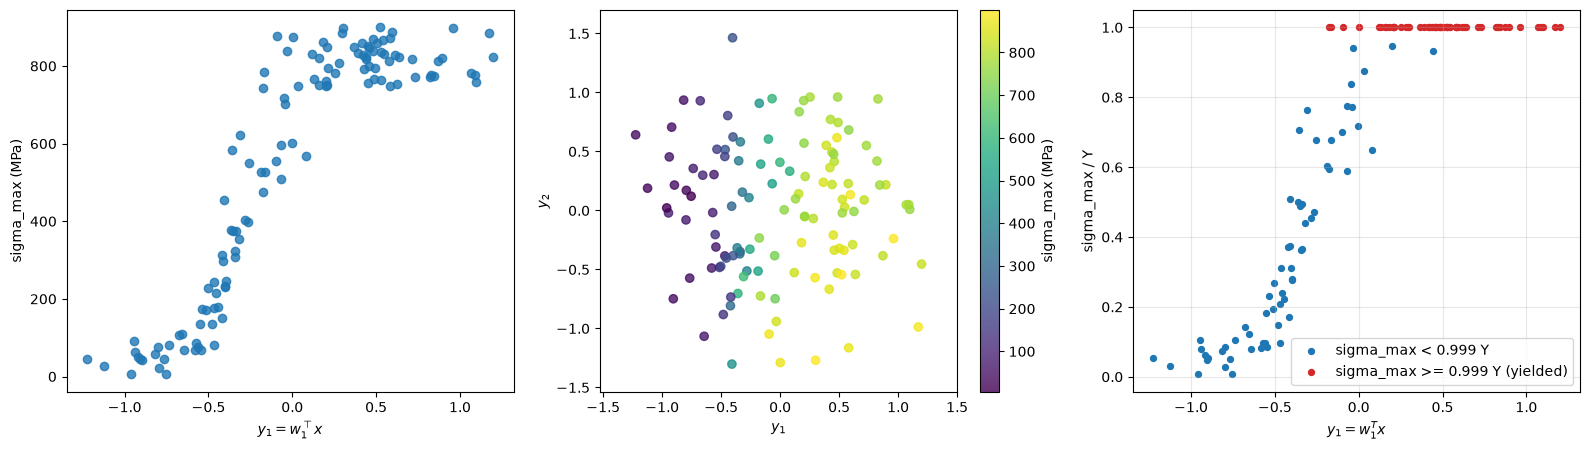

In [8]:
Z = space.to_normalized(X)
Y = Z @ sub.W[:, :2]
E_line = X[:, 1] / X[:, 0]                       # line energy P/v (J/mm)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 1), X=X, f=smax, dims=1,
                                    qoi_label='sigma_max (MPa)', ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=smax, dims=2,
                                    qoi_label='sigma_max (MPa)', ax=axes[1])
axes[2].scatter(Y[~sat, 0], r[~sat], c='C0', s=18, label='sigma_max < 0.999 Y')
axes[2].scatter(Y[sat, 0], r[sat], c='C3', s=18, label='sigma_max >= 0.999 Y (yielded)')
axes[2].set_xlabel('$y_1 = w_1^T x$'); axes[2].set_ylabel('sigma_max / Y'); axes[2].legend(); axes[2].grid(alpha=0.3)
fig.tight_layout(); plt.close(fig)
print(f'corr(y1, sigma_max) = {np.corrcoef(Y[:, 0], smax)[0, 1]:.3f}; corr(y1, P/v) = {np.corrcoef(Y[:, 0], E_line)[0, 1]:.3f}; '
      f'corr(y1, log(P/v)) = {np.corrcoef(Y[:, 0], np.log(E_line))[0, 1]:.3f}')
print(f'yielded runs: y1 in [{Y[sat, 0].min():.3f}, {Y[sat, 0].max():.3f}]; runs below yield: y1 in [{Y[~sat, 0].min():.3f}, {Y[~sat, 0].max():.3f}]')
print(f'runs with y1 > {Y[~sat, 0].max():.3f}: {np.sum(Y[:, 0] > Y[~sat, 0].max())}, all yielded; '
      f'runs with y1 < {Y[sat, 0].min():.3f}: {np.sum(Y[:, 0] < Y[sat, 0].min())}, none yielded')
fig

$\sigma_{\max}$ rises with $y_1$ (correlation 0.888) and then levels off at the yield strength. The active variable separates the two regimes: the 57 runs that yield have $y_1 \in [-0.177, 1.199]$, the others $y_1 \in [-1.225, 0.440]$; all 34 runs with $y_1 > 0.440$ yielded and none of the 51 runs with $y_1 < -0.177$ did. In the plateau $\sigma_{\max} = Y$, which varies by ±10 % independently of $y_1$; that, and the transition band between the two regimes, make up most of the scatter at fixed $y_1$. The active variable is correlated with the line energy $P/v$ (0.697) and more strongly with $\log(P/v)$ (0.851), the usual process-map variable for powder bed fusion.

**Cross-checks.** Local linear gradients (each from a linear fit to the 10 nearest runs) and a global linear fit find the same first direction.

In [9]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    gll = ac.local_linear_gradients(X=X, f=smax, space=space)
    sll = ac.active_subspace(space=space, grads=gll, nboot=NBOOT, rng=SEED)
    sols = ac.active_subspace(space=space, X=X, f=smax, estimator='ols', n=1)
sll = ac.orient(sll, by='reference', reference=sub, columns=2)
lll = sll.eigenvalues
print(f'local linear (p = {int(np.floor(1.7 * m))} neighbours): lambda1/lambda2 = {lll[0] / lll[1]:.2f}, lambda2/lambda3 = {lll[1] / lll[2]:.2f}; '
      f'|w1_LL . w1_QPHD| = {abs(sll.W[:, 0] @ sub.W[:, 0]):.3f}, |w2_LL . w2_QPHD| = {abs(sll.W[:, 1] @ sub.W[:, 1]):.3f}')
print('  w1_LL =', np.array2string(sll.W[:, 0], precision=3), ' w2_LL =', np.array2string(sll.W[:, 1], precision=3))
print(f'OLS (global linear fit): |w_OLS . w1_QPHD| = {abs(sols.W[:, 0] @ sub.W[:, 0]):.3f}; w_OLS =', np.array2string(sols.W[:, 0], precision=3))

local linear (p = 10 neighbours): lambda1/lambda2 = 6.66, lambda2/lambda3 = 1.70; |w1_LL . w1_QPHD| = 0.991, |w2_LL . w2_QPHD| = 0.106
  w1_LL = [-0.408  0.903 -0.081 -0.047  0.045 -0.084]  w2_LL = [ 0.235  0.091  0.222  0.305  0.888 -0.072]
OLS (global linear fit): |w_OLS . w1_QPHD| = 0.995; w_OLS = [-0.395  0.901 -0.088  0.022  0.135 -0.07 ]


The local linear first direction agrees with QPHD's ($|\mathbf w_1^{\mathrm{LL}}\cdot\mathbf w_1| = 0.991$), with a smaller first gap (6.66) because the local fits keep the curvature and the kink that the quadratic smooths out. Its second direction is mostly elastic modulus and differs from QPHD's (0.106), another sign that no second direction is resolved by 120 runs. The global linear fit gives $|\mathbf w_{\mathrm{OLS}}\cdot\mathbf w_1| = 0.995$.

**Robustness of $n = 1$.** The choice rests on a global quadratic that cannot follow the kink at yield (LOO $R^2 = 0.8093$) and on a ratio with a wide bootstrap interval. The cell checks it in four ways that the data allow: (i) the bootstrap distribution of $\lambda_1/\lambda_2$; (ii) QPHD on the runs below yield only, on $\sigma_{\max}/Y$, on $\log\sigma_{\max}$, and with Table 1's bounds for $E$ and $\rho$ (written out in numpy, because the library rejects points outside its space; the cell first checks that the numpy version reproduces the library's eigenvalues); (iii) a quadratic with the yield cap built in, $\sigma_{\max} \approx \min(Y, q(\mathbf x))$, whose $\mathbf C$ is computed by Monte Carlo from the gradient of the capped function; (iv) the 100 validation runs, which the estimate never saw: at each of the two fixed $(v, P)$ designs, a linear fit in $(T_0, Y, E, \rho)$ gives a direction to compare with the corresponding components of $\mathbf w_1$. Training and validation runs are not pooled into one $\mathbf C$: the validation runs sit at two $(v, P)$ points, not on the uniform density, and pooling them would inflate the gap.

In [10]:
# (i) the bootstrap distribution of lambda1/lambda2 (the replicates of the estimate above)
print(f'pairs bootstrap ({NBOOT} replicates): median lambda1/lambda2 = {np.median(ratio_b):.1f} (full sample {lam[0] / lam[1]:.1f}); '
      f'fraction of replicates with lambda1/lambda2 < 10: {np.mean(ratio_b < 10):.2f}')


# (ii) QPHD on variants of the data. The library refuses points outside its space (Table 1's bounds), so the
#      same estimator is written out in numpy: C = g g^T + H H / 3 from the least-squares quadratic in [-1, 1]^6.
def quad_design(Zs):
    k = Zs.shape[1]
    return np.column_stack([np.ones(len(Zs))] + [Zs[:, j] for j in range(k)] +
                           [Zs[:, j] * Zs[:, l] for j, l in itertools.combinations_with_replacement(range(k), 2)])


def grad_hess(c, k=m):
    """Gradient at 0 and Hessian of the quadratic with coefficients c (order of quad_design)."""
    g, H = c[1:k + 1], np.zeros((k, k))
    for (j, l), v in zip(itertools.combinations_with_replacement(range(k), 2), c[k + 1:]):
        H[j, l] = H[l, j] = 2 * v if j == l else v
    return g, H


def eig_desc(Cm):
    lv, Vv = np.linalg.eigh(Cm)
    return lv[::-1], Vv[:, ::-1]


def qphd_np(Zs, fs):
    """QPHD eigenpairs, in-sample R^2 and LOO R^2 of the least-squares quadratic."""
    A_ = quad_design(Zs)
    c = np.linalg.lstsq(A_, fs, rcond=None)[0]
    g, H = grad_hess(c, Zs.shape[1])
    lv, Vv = eig_desc(np.outer(g, g) + H @ H / 3)
    res = fs - A_ @ c
    res_loo = res / (1 - np.einsum('ij,ji->i', A_, np.linalg.pinv(A_)))
    sst_ = np.sum((fs - fs.mean())**2)
    return lv, Vv, 1 - res @ res / sst_, 1 - res_loo @ res_loo / sst_


w1 = sub.W[:, 0]
print(f'numpy QPHD vs the library on all 120 runs: largest relative eigenvalue difference '
      f'{np.max(np.abs(qphd_np(Z, smax)[0] - lam) / lam):.1e}')
Z1 = 2 * (X - t1lo) / (t1hi - t1lo) - 1                 # inputs normalized with Table 1's bounds for E and rho
variants = [('all 120 runs (the estimate above)', Z, smax), (f'the {(~sat).sum()} runs below yield', Z[~sat], smax[~sat]),
            ('sigma_max / Y', Z, smax / X[:, 3]), ('log sigma_max', Z, np.log(smax)),
            ("Table 1's bounds for E and rho", Z1, smax)]
print(f"\n{'QPHD on':36s} {'M':>4s} {'l1/l2':>7s} {'l2/l3':>6s} {'|w1.w1|':>8s} {'R^2':>6s} {'LOO R^2':>8s}")
for name, Zs, fs in variants:
    lv, Vv, r2_, loo_ = qphd_np(Zs, fs)
    print(f'{name:36s} {len(fs):4d} {lv[0] / lv[1]:7.1f} {lv[1] / lv[2]:6.2f} {abs(Vv[:, 0] @ w1):8.3f} {r2_:6.3f} {loo_:8.3f}')

# (iii) a quadratic with the yield cap built in, sigma_max ~ min(Y, q(x)) with q quadratic (28 coefficients), fitted by
#       nonlinear least squares started from the quadratic of the runs below yield; LOO by refitting 120 times
A = quad_design(Z)


def fit_capped(keep):
    start = np.linalg.lstsq(A[keep & ~sat], smax[keep & ~sat], rcond=None)[0]
    return least_squares(lambda c: np.minimum(X[keep, 3], A[keep] @ c) - smax[keep], start).x


c_cap = fit_capped(np.ones(len(X), bool))
res_cap = np.minimum(X[:, 3], A @ c_cap) - smax
loo_cap = np.array([min(X[i, 3], A[i] @ fit_capped(np.arange(len(X)) != i)) - smax[i] for i in range(len(X))])
sst = np.sum((smax - smax.mean())**2)
# C of the capped function by Monte Carlo over the uniform density: where q < Y the gradient is that of q; where
# q >= Y the function is Y itself, whose gradient in normalized coordinates is (upper - lower)/2 along the Y axis
Zmc = np.random.default_rng(SEED).uniform(-1, 1, (200_000, m))
g_c, H_c = grad_hess(c_cap)
below = quad_design(Zmc) @ c_cap < space.from_normalized(Zmc)[:, 3]
G = (g_c + Zmc @ H_c) * below[:, None]
G[:, 3] += (~below) * (hi[3] - lo[3]) / 2
l_cap, V_cap = eig_desc(G.T @ G / len(G))
l_q, V_q = eig_desc(np.outer(g_c, g_c) + H_c @ H_c / 3)
pred_cap_v = np.minimum(Xv[:, 3], quad_design(space.to_normalized(Xv)) @ c_cap)
print(f'\ncapped quadratic min(Y, q): R^2 = {1 - res_cap @ res_cap / sst:.3f}, LOO R^2 = {1 - loo_cap @ loo_cap / sst:.3f} '
      f'(plain quadratic: {r2_in:.3f}, {quad.loo_r_squared:.3f}); LOO RMSE {np.sqrt(np.mean(loo_cap**2)):.1f} MPa')
print(f'   C of min(Y, q) (200,000 uniform samples; q >= Y on {np.mean(~below):.3f} of the box): lambda1/lambda2 = {l_cap[0] / l_cap[1]:.1f}, '
      f'lambda2/lambda3 = {l_cap[1] / l_cap[2]:.2f}, |w1 . w1| = {abs(V_cap[:, 0] @ w1):.3f}; w1 =', np.array2string(V_cap[:, 0], precision=3))
print(f'   C of q alone: lambda1/lambda2 = {l_q[0] / l_q[1]:.0f}, |w1 . w1| = {abs(V_q[:, 0] @ w1):.3f}')
print(f'   on the 100 validation runs: RMSE = {np.sqrt(np.mean((pred_cap_v - smax_v)**2)):.1f} MPa, '
      f'R^2 = {1 - np.sum((pred_cap_v - smax_v)**2) / np.sum((smax_v - smax_v.mean())**2):.3f}')

# (iv) the validation runs as an independent check: at each fixed (v, P), a linear fit in normalized (T0, Y, E, rho)
#      gives a direction, compared with w1's (T0, Y, E, rho) components (the runs were not used for w1)
Zv = space.to_normalized(Xv)
w1u = w1[2:] / np.linalg.norm(w1[2:])
print(f'\nw1 restricted to (T0, Y, E, rho): length {np.linalg.norm(w1[2:]):.3f}, direction', np.array2string(w1u, precision=3))
dirs = []
for d in designs:
    blk = np.all(Xv[:, :2] == d, axis=1)
    A1 = np.column_stack([np.ones(blk.sum()), Zv[blk, 2:]])
    b = np.linalg.lstsq(A1, smax_v[blk], rcond=None)[0]
    res = smax_v[blk] - A1 @ b
    u = b[1:] / np.linalg.norm(b[1:])
    dirs.append(u)
    print(f'validation design ({d[0]}, {d[1]}): linear R^2 = {1 - res @ res / np.sum((smax_v[blk] - smax_v[blk].mean())**2):.3f}; '
          f'direction', np.array2string(u, precision=3), f'; |cos| with w1 restricted = {abs(u @ w1u):.3f} (same signs: {u @ w1u > 0})')
print(f'|cos| between the two validation directions = {abs(dirs[0] @ dirs[1]):.3f}')

pairs bootstrap (300 replicates): median lambda1/lambda2 = 14.6 (full sample 28.1); fraction of replicates with lambda1/lambda2 < 10: 0.26
numpy QPHD vs the library on all 120 runs: largest relative eigenvalue difference 5.4e-14

QPHD on                                 M   l1/l2  l2/l3  |w1.w1|    R^2  LOO R^2
all 120 runs (the estimate above)     120    28.1   1.89    1.000  0.891    0.809
the 63 runs below yield                63    64.5   9.96    0.966  0.961    0.815
sigma_max / Y                         120    36.2   1.67    0.999  0.892    0.811
log sigma_max                         120    31.9   4.88    0.991  0.885    0.793
Table 1's bounds for E and rho        120    26.3   1.88    0.999  0.891    0.809



capped quadratic min(Y, q): R^2 = 0.990, LOO R^2 = 0.956 (plain quadratic: 0.891, 0.809); LOO RMSE 66.2 MPa
   C of min(Y, q) (200,000 uniform samples; q >= Y on 0.477 of the box): lambda1/lambda2 = 58.0, lambda2/lambda3 = 2.31, |w1 . w1| = 0.989; w1 = [-0.453  0.881 -0.054 -0.079  0.083 -0.044]
   C of q alone: lambda1/lambda2 = 168, |w1 . w1| = 0.974
   on the 100 validation runs: RMSE = 43.5 MPa, R^2 = 0.855

w1 restricted to (T0, Y, E, rho): length 0.192, direction [-0.296 -0.276  0.815 -0.415]
validation design (417.3, 82.97): linear R^2 = 0.996; direction [-0.352 -0.425  0.755 -0.355] ; |cos| with w1 restricted = 0.984 (same signs: True)
validation design (614.5, 115.8): linear R^2 = 0.903; direction [-0.376 -0.296  0.79  -0.384] ; |cos| with w1 restricted = 0.996 (same signs: True)
|cos| between the two validation directions = 0.990


The full-sample ratio is optimistic: the bootstrap median of $\lambda_1/\lambda_2$ is 14.6, about half the full-sample 28.1, and 0.26 of the replicates have a ratio below 10. The direction itself is stable. QPHD on the 63 runs below yield, where there is no kink, gives $\lambda_1/\lambda_2 = 64.5$ and $|\mathbf w_1\cdot\mathbf w_1| = 0.966$; on $\sigma_{\max}/Y$ and $\log\sigma_{\max}$ the agreement is 0.999 and 0.991; and with Table 1's bounds for $E$ and $\rho$ it is 0.999 ($\lambda_1/\lambda_2 = 26.3$), so the choice between the two sets of bounds does not matter. The capped quadratic fits far better than the plain one (LOO $R^2 = 0.956$ against 0.809; in-sample 0.990 against 0.891) and predicts the validation runs better than the degree-4 polynomial below (RMSE 43.5 against 51.9 MPa, $R^2$ 0.855 against 0.794). Its $\mathbf C$ has $\lambda_1/\lambda_2 = 58.0$ and $|\mathbf w_1\cdot\mathbf w_1| = 0.989$, and the uncapped $q$ inside it has $\lambda_1/\lambda_2 = 168$. At each validation design $\sigma_{\max}$ is nearly linear in $(T_0, Y, E, \rho)$ (linear $R^2$ = 0.996 and 0.903), the two fitted directions agree with each other ($|\cos| = 0.990$), and they agree with $\mathbf w_1$'s components in those inputs ($|\cos|$ = 0.984 and 0.996, with the same signs). Those components are small (their length in $\mathbf w_1$ is 0.192), so this confirms the minor part of $\mathbf w_1$, $E$ (+) against $T_0$, $Y$ and $\rho$ (−), on runs the estimate never saw; it cannot test the $(v, P)$ part, which the validation runs hold fixed.

**Temperature context.** The paper constrains the designs by the peak temperature $T_{\max}$ at the centroid of the top surface during the moving-heat step, $T_{\mathrm{liq}} < T_{\max} < 1.1\,T_{\mathrm{liq}}$ (Eq. 17), which the published files do not contain. The first frame of the cooling step is the end of the moving-heat step, so the temperature stored there at a point is a **lower bound** on that point's peak temperature. Two points matter: element 1452 at the centroid of the top surface, where $T_{\max}$ is defined, and element 12 on the same scan track, 62.5 µm before its end, which the beam passes last. The cell also checks that source file $i$ belongs to input row $i - 1$.

In [11]:
T_SOL, T_LIQ, T_HI = 1605.0, 1650.0, 1815.0          # solidus, liquidus, 1.1 T_liq (degC; Sect. 5.1, Eq. 17)
T12, T1452, T2988 = Ttr[:, 1], Ttr[:, 2], Ttr[:, 4]    # end of the track, centroid of the top surface, x = 0
print(f'row mapping checks: corr(T at x = 0, T0) = {np.corrcoef(T2988, X[:, 2])[0, 1]:.3f}; '
      f'corr(T_e12, log(P/v)) = {np.corrcoef(T12, np.log(E_line))[0, 1]:.3f}; corr(T_e12, y1) = {np.corrcoef(T12, Y[:, 0])[0, 1]:.3f}')
print(f'centroid of the top surface (e1452): cooling-start T in [{T1452.min():.0f}, {T1452.max():.0f}] degC; '
      f'runs at or above T_sol: {np.sum(T1452 >= T_SOL)}')
print(f'end of the track (e12): cooling-start T in [{T12.min():.0f}, {T12.max():.0f}] degC, median {np.median(T12):.0f}')
for name, thr in (('T_sol = 1605', T_SOL), ('T_liq = 1650', T_LIQ), ('1.1 T_liq = 1815', T_HI)):
    print(f'   training runs with T_e12 >= {name} degC: {np.sum(T12 >= thr)} of {len(T12)}')
print(f'yielded runs with T_e12 >= T_sol: {np.sum(sat & (T12 >= T_SOL))} of {sat.sum()}; '
      f'runs with T_e12 < T_sol: {np.sum(T12 < T_SOL)}, of which yielded: {np.sum(sat & (T12 < T_SOL))}')
for d in designs:
    blk = np.all(Xv[:, :2] == d, axis=1)
    print(f'validation design ({d[0]}, {d[1]}): T_e12 in [{Tva[blk, 1].min():.0f}, {Tva[blk, 1].max():.0f}] degC, '
          f'>= 1.1 T_liq in {np.sum(Tva[blk, 1] >= T_HI)} of {blk.sum()} runs; T_e1452 at most {Tva[blk, 2].max():.0f} degC')
print(f'training row {np.argmin(smax)} (smallest sigma_max): T_e12 = {T12[np.argmin(smax)]:.0f} degC, T_e1452 = {T1452[np.argmin(smax)]:.0f} degC')

row mapping checks: corr(T at x = 0, T0) = 1.000; corr(T_e12, log(P/v)) = 0.917; corr(T_e12, y1) = 0.958
centroid of the top surface (e1452): cooling-start T in [751, 1452] degC; runs at or above T_sol: 0
end of the track (e12): cooling-start T in [895, 3404] degC, median 1910
   training runs with T_e12 >= T_sol = 1605 degC: 84 of 120
   training runs with T_e12 >= T_liq = 1650 degC: 82 of 120
   training runs with T_e12 >= 1.1 T_liq = 1815 degC: 66 of 120
yielded runs with T_e12 >= T_sol: 57 of 57; runs with T_e12 < T_sol: 36, of which yielded: 0
validation design (417.3, 82.97): T_e12 in [1747, 1896] degC, >= 1.1 T_liq in 25 of 50 runs; T_e1452 at most 1045 degC
validation design (614.5, 115.8): T_e12 in [1886, 2036] degC, >= 1.1 T_liq in 50 of 50 runs; T_e1452 at most 1130 degC
training row 106 (smallest sigma_max): T_e12 = 1018 degC, T_e1452 = 772 degC


The row mapping holds: under it the temperature at $x = 0$ follows $T_0$ with correlation 1.000, and the temperature at element 12 follows $\log(P/v)$ (0.917). At the centroid the bound is uninformative: by the end of the scan that point has cooled to at most 1452 °C, below the solidus in every run. At element 12 the cooling-start temperature ranges from 895 to 3404 °C (median 1910): 84 of the 120 training runs are at or above the solidus there, 82 at or above $T_{\mathrm{liq}}$, and 66 at or above $1.1\,T_{\mathrm{liq}} = 1815$ °C, so in at least 66 runs the end of the track was heated beyond $1.1\,T_{\mathrm{liq}}$. All 57 yielded runs are among the 84 at or above the solidus; none of the 36 runs below it yielded. The active variable tracks this temperature closely (correlation 0.958), so $\mathbf w_1$ largely follows the passage from runs whose track end stays below the solidus to strongly overheated ones. These counts are lower bounds at element 12, **not** bounds on $T_{\max}$: at the paper's two optimal designs, which its optimizer chose subject to Eq. (17), element 12 reaches $1.1\,T_{\mathrm{liq}}$ in 25 and in 50 of the 50 runs, so the end of the track runs hotter than the centroid, and the training counts cannot be read as violations of Eq. (17). The run with the smallest $\sigma_{\max}$ (row 106) has 1018 °C at element 12, below the solidus, which is consistent with, but does not prove, a run that did not melt the powder.

### Surrogate on the active variable

Polynomials of degree 1–4 in one and two active variables, scored by leave-one-out $R^2$ (the subspace is held fixed at the full-sample estimate, so these values are slightly optimistic). The chosen surrogate is then tested on the 100 validation runs, which the subspace and the fit have not seen: 50 at each of the paper's two validated optimal designs, $(v, P) = (417.3\ \mathrm{mm/s}, 82.97\ \mathrm W)$ and $(614.5\ \mathrm{mm/s}, 115.8\ \mathrm W)$, with random $(T_0, Y, E, \rho)$.

1-D active variable(s), LOO R^2 for degree 1..4: 0.7812  0.8506  0.8914  0.9214
2-D active variable(s), LOO R^2 for degree 1..4: 0.7842  0.8536  0.9057  0.9016
chosen: 1-D, degree 4, LOO R^2 = 0.9214
fitted values on the training runs: [-34.3, 841.3] MPa (9 below 0 MPa, 31 above the run's Y)
on the 100 validation runs: RMSE = 51.9 MPa, R^2 = 0.794 (training LOO RMSE 88.2 MPa)
  design (417.3, 82.97): FEM sigma_max mean 601.2, sd 112.5; surrogate mean 539.6, sd 103.1 MPa
  design (614.5, 115.8): FEM sigma_max mean 691.4, sd 99.2; surrogate mean 683.2, sd 77.7 MPa
y1: training runs in [-1.225, 1.199], sd 0.571
  validation design (417.3, 82.97): y1 in [-0.379, 0.057], mean -0.176, sd 0.116; smallest FEM sigma_max 385.9 MPa (training: 5.27)
  validation design (614.5, 115.8): y1 in [-0.224, 0.231], mean 0.010, sd 0.115; smallest FEM sigma_max 474.1 MPa (training: 5.27)


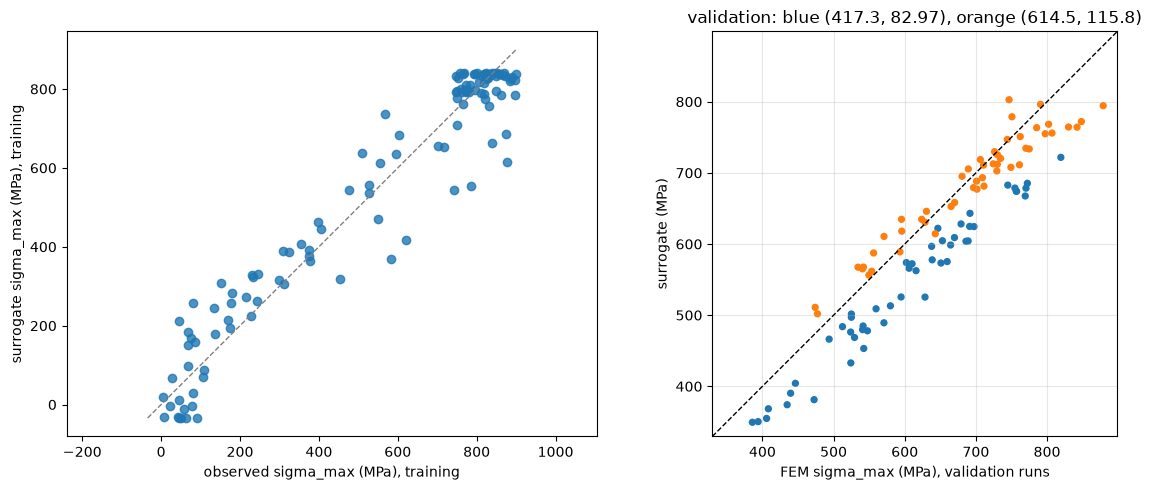

In [12]:
loo = {}
for n_ in (1, 2):
    for deg in (1, 2, 3, 4):
        s = ac.fit_surrogate(X=X, f=smax, space=space, subspace=ac.with_dimension(sub, n_), kind='poly', degree=deg)
        loo[(n_, deg)] = s.loo_r_squared
    print(f'{n_}-D active variable(s), LOO R^2 for degree 1..4:', '  '.join(f'{loo[(n_, d)]:.4f}' for d in (1, 2, 3, 4)))
best = max(loo, key=loo.get)
srg = ac.fit_surrogate(X=X, f=smax, space=space, subspace=ac.with_dimension(sub, best[0]), kind='poly', degree=best[1])
print(f'chosen: {best[0]}-D, degree {best[1]}, LOO R^2 = {srg.loo_r_squared:.4f}')
fit_tr = smax - srg.residuals
print(f'fitted values on the training runs: [{fit_tr.min():.1f}, {fit_tr.max():.1f}] MPa ({np.sum(fit_tr < 0)} below 0 MPa, {np.sum(fit_tr > X[:, 3])} above the run\'s Y)')
Yv = space.to_normalized(Xv) @ sub.W[:, :best[0]]
pred_v = srg.evaluate(Yv)
rmse_v = np.sqrt(np.mean((pred_v - smax_v)**2))
r2_v = 1 - np.sum((pred_v - smax_v)**2) / np.sum((smax_v - smax_v.mean())**2)
print(f'on the 100 validation runs: RMSE = {rmse_v:.1f} MPa, R^2 = {r2_v:.3f} (training LOO RMSE '
      f'{np.sqrt(np.mean(srg.loo_residuals**2)):.1f} MPa)')
for d in designs:
    blk = np.all(Xv[:, :2] == d, axis=1)
    print(f'  design ({d[0]}, {d[1]}): FEM sigma_max mean {smax_v[blk].mean():.1f}, sd {smax_v[blk].std(ddof=1):.1f}; '
          f'surrogate mean {pred_v[blk].mean():.1f}, sd {pred_v[blk].std(ddof=1):.1f} MPa')
print(f'y1: training runs in [{Y[:, 0].min():.3f}, {Y[:, 0].max():.3f}], sd {Y[:, 0].std(ddof=1):.3f}')
for d in designs:
    blk = np.all(Xv[:, :2] == d, axis=1)
    yv = space.to_normalized(Xv[blk]) @ sub.W[:, 0]
    print(f'  validation design ({d[0]}, {d[1]}): y1 in [{yv.min():.3f}, {yv.max():.3f}], mean {yv.mean():.3f}, sd {yv.std(ddof=1):.3f}; '
          f'smallest FEM sigma_max {smax_v[blk].min():.1f} MPa (training: {smax.min():.2f})')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ac.plotting.plot_surrogate_fit(srg, X=X, f=smax, qoi_label='sigma_max (MPa), training', ax=axes[0])
axes[1].scatter(smax_v, pred_v, s=18, c=np.where(Xv[:, 0] == designs[0, 0], 'C0', 'C1'))
lim = [min(smax_v.min(), pred_v.min()) - 20, max(smax_v.max(), pred_v.max()) + 20]
axes[1].plot(lim, lim, 'k--', lw=1); axes[1].set_xlim(lim); axes[1].set_ylim(lim); axes[1].set_aspect('equal')
axes[1].set_xlabel('FEM sigma_max (MPa), validation runs'); axes[1].set_ylabel('surrogate (MPa)')
axes[1].set_title('validation: blue (417.3, 82.97), orange (614.5, 115.8)'); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.close(fig)
fig

A second active variable adds little: the best one-dimensional polynomial (degree 4) has LOO $R^2 = 0.9214$, the best two-dimensional one (degree 3) 0.9057. A polynomial cannot follow the yield plateau exactly: its fitted values on the training runs range from −34.3 to 841.3 MPa, 9 of them below zero and 31 above the run's own yield strength, so a surrogate meant for use should be clipped to $[0, Y]$ or built in a form such as $\min(Y, g(y_1))$; the capped quadratic in all six inputs above is of that kind and predicts the validation runs better (RMSE 43.5 MPa). On the validation runs the degree-4 polynomial in $y_1$ has RMSE 51.9 MPa and $R^2 = 0.794$, against a training LOO RMSE of 88.2 MPa; the validation designs sit in the middle of the active variable's range ($y_1 \in [-0.379, 0.057]$ and $[-0.224, 0.231]$, standard deviations 0.116 and 0.115, against $[-1.225, 1.199]$ and 0.571 for the training runs), away from the low-stress tail (smallest validation $\sigma_{\max}$ 385.9 and 474.1 MPa, against 5.27 MPa in training). It predicts the mean of $\sigma_{\max}$ well at the faster design (683.2 against 691.4 MPa) and too low at the slower one (539.6 against 601.2 MPa), and with one active variable it misses part of the spread caused by $(T_0, Y, E, \rho)$ (standard deviations 103.1 and 77.7 MPa, against 112.5 and 99.2 MPa in the FEM runs).

### The paper's stress features

The paper does not compute an active subspace of $\sigma_{\max}$. It decomposes the matrix of stress fields $\mathbf S \in \mathbb R^{120\times448}$ by an uncentred SVD, takes the features $\mathbf F = \mathbf U_k\boldsymbol\Sigma_k$ (Eq. 14), and fits each feature on its own active variables (Table 2): feature 1 with one active variable and a parabola ($R^2 = 0.9665$), feature 2 with two and a fifth-degree surface ($R^2 = 0.9074$). The method used to estimate those active subspaces is not stated. The cell repeats this with QPHD and reports in-sample $R^2$ (which the paper's $R^2 = 1 - \mathsf{SS}_{\mathrm{res}}/\mathsf{SS}_{\mathrm{tot}}$ appears to be) and LOO $R^2$. Feature signs are arbitrary.

feature 1: lambda1/lambda2 = 34.6, lambda2/lambda3 = 2.30; |w1 . w1(sigma_max)| = 0.975; w1 = [-0.511  0.835  0.056 -0.035  0.163 -0.102]
   1-D, degree 2: R^2 = 0.9260 (paper Table 2: 0.9665), LOO R^2 = 0.9196


feature 2: lambda1/lambda2 = 4.0, lambda2/lambda3 = 5.91; |w1 . w1(sigma_max)| = 0.752; w1 = [-0.835  0.491  0.179 -0.088  0.145  0.025]
   2-D, degree 5: R^2 = 0.9321 (paper Table 2: 0.9074), LOO R^2 = 0.8706
corr(feature 1, sigma_max) = -0.835
feature 1 in [-12518, -64] MPa over y1 in [-1.27, 1.21]; corr(y1, feature 1) = -0.948


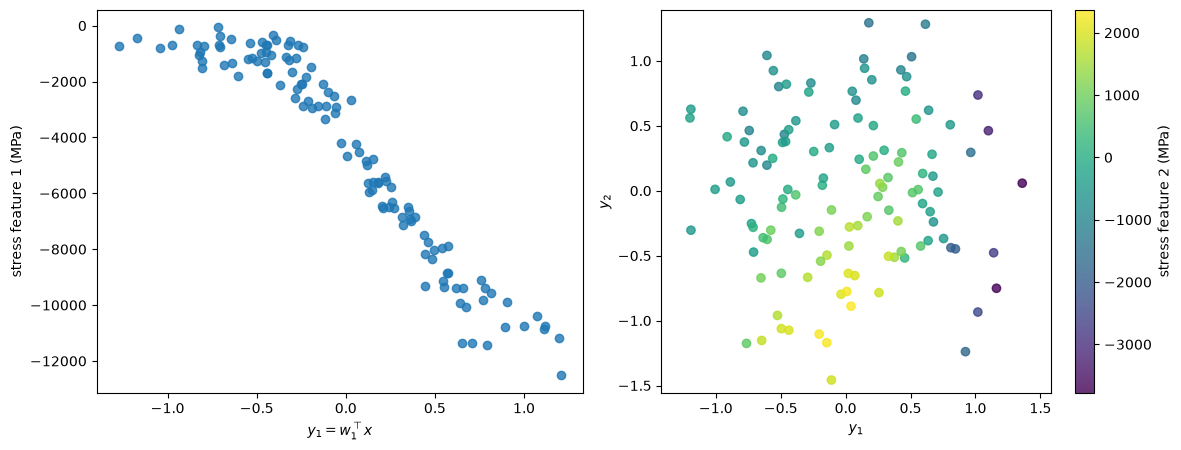

In [13]:
F = U_ * s_                                   # features, Eq. (14): F = U_k Sigma_k (uncentred SVD)
feat = {}
for j, (n_, deg, paper_r2) in {1: (1, 2, 0.9665), 2: (2, 5, 0.9074)}.items():
    fj = F[:, j - 1]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sj = ac.active_subspace(space=space, X=X, f=fj, estimator='qphd', nboot=NBOOT, rng=SEED)
    sj = ac.orient(sj, by='reference', reference=sub, columns=1)   # w1 signed like sigma_max's (P > 0)
    g = ac.fit_surrogate(X=X, f=fj, space=space, subspace=ac.with_dimension(sj, n_), kind='poly', degree=deg)
    r2 = 1 - np.sum(g.residuals**2) / np.sum((fj - fj.mean())**2)
    feat[j] = dict(sub=sj, r2=r2, loo=g.loo_r_squared, paper=paper_r2, n=n_, deg=deg)
    lj = sj.eigenvalues
    print(f'feature {j}: lambda1/lambda2 = {lj[0] / lj[1]:.1f}, lambda2/lambda3 = {lj[1] / lj[2]:.2f}; '
          f'|w1 . w1(sigma_max)| = {abs(sj.W[:, 0] @ sub.W[:, 0]):.3f}; w1 =', np.array2string(sj.W[:, 0], precision=3))
    print(f'   {n_}-D, degree {deg}: R^2 = {r2:.4f} (paper Table 2: {paper_r2}), LOO R^2 = {g.loo_r_squared:.4f}')
print(f'corr(feature 1, sigma_max) = {np.corrcoef(F[:, 0], smax)[0, 1]:.3f}')
y1f = space.to_normalized(X) @ feat[1]['sub'].W[:, 0]
print(f'feature 1 in [{F[:, 0].min():.0f}, {F[:, 0].max():.0f}] MPa over y1 in [{y1f.min():.2f}, {y1f.max():.2f}]; corr(y1, feature 1) = {np.corrcoef(y1f, F[:, 0])[0, 1]:.3f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ac.plotting.plot_sufficient_summary(ac.with_dimension(feat[1]['sub'], 1), X=X, f=F[:, 0], dims=1,
                                    qoi_label='stress feature 1 (MPa)', ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(feat[2]['sub'], 2), X=X, f=F[:, 1], dims=2,
                                    qoi_label='stress feature 2 (MPa)', ax=axes[1])
fig.tight_layout(); plt.close(fig)
fig

Feature 1 has one dominant direction ($\lambda_1/\lambda_2 = 34.6$), nearly the same as that of $\sigma_{\max}$ ($|\mathbf w_1\cdot\mathbf w_1^{\sigma}| = 0.975$; the feature is anti-correlated with $\sigma_{\max}$, −0.835, because of the SVD sign), and a parabola in it gives $R^2 = 0.9260$, below the paper's 0.9665. The feature runs from −64 to −12,518 MPa over $y_1 \in [-1.27, 1.21]$, decreasing (correlation −0.948); the paper's Fig. 7(a) shows the same decreasing, flattening trend over about $[-1.3, 1.2]$, with its lowest point, read from the figure, near $-1.25\times10^4$ at $\eta_1 \approx 1.2$. Feature 2's spectrum has its largest gap after the second eigenvalue ($\lambda_1/\lambda_2 = 4.0$, $\lambda_2/\lambda_3 = 5.91$), consistent with the paper's two active variables, and a fifth-degree surface in them gives $R^2 = 0.9321$ (LOO 0.8706), against the paper's 0.9074.

### The paper's validation (Table 4)

Table 4 reports the 0.95-superquantile of $\sigma_{\max}$ from the 50 FEM runs at each optimal design: $\bar Q^{\mathsf{FEM}}_{0.95} = 768.12$ MPa at (417.3, 83.0) and 790.69 MPa at (614.5, 115.8). The cell computes it from the stored validation runs in two ways: the empirical superquantile (Eq. 9 with the empirical 0.95-quantile), with a bootstrap interval (the spread that a fresh set of 50 runs would show), and Eq. (9) with the paper's optimal auxiliary variable $\zeta^*$ in place of the quantile, as Sect. 5.4 describes (709.5 and 743.8 MPa, the COBYLA results of Table 3 at these designs). It then tries other estimators: the eight quantile conventions of `np.quantile`, the levels $\alpha = 0.90$ and $0.975$, the mean of the largest 3 of 50 values, and $\sigma_{\max}$ of the validation fields projected on the first five right singular vectors of the training fields (the paper's $K_S = 5$, without surrogate error).

In [14]:
def cvar(x, a=0.95, method='linear'):
    """Empirical a-superquantile: q + E[(x - q)+]/(1 - a), q the empirical a-quantile (Eq. 9)."""
    q = np.quantile(x, a, method=method)
    return q + np.mean(np.maximum(x - q, 0)) / (1 - a)


QMETHODS = ('linear', 'lower', 'higher', 'nearest', 'inverted_cdf', 'hazen', 'weibull', 'median_unbiased')
smax_v5 = ((Sva @ Vt_[:5].T) @ Vt_[:5]).max(axis=1)   # sigma_max of the validation fields projected on the first
                                                      # 5 right singular vectors of the training fields (K_S = 5)


rng = np.random.default_rng(SEED)
paper_t4 = {417.3: (709.5, 768.12, 762.08), 614.5: (743.8, 790.69, 804.89)}   # zeta* (Table 3, COBYLA), Table 4
t4 = {}
for d in designs:
    s = smax_v[np.all(Xv[:, :2] == d, axis=1)]
    zeta, q_fem, q_surr = paper_t4[d[0]]
    boot = np.array([cvar(rng.choice(s, len(s))) for _ in range(2000)])
    t4[d[0]] = (cvar(s), *np.percentile(boot, [2.5, 97.5]), zeta + np.mean(np.maximum(s - zeta, 0)) / 0.05,
                np.quantile(s, 0.95), s.max())
    print(f'design ({d[0]}, {d[1]}): empirical Qbar_0.95 = {t4[d[0]][0]:.1f} MPa (bootstrap 95% [{t4[d[0]][1]:.1f}, {t4[d[0]][2]:.1f}]); '
          f'with zeta* = {zeta} in Eq. (9): {t4[d[0]][3]:.1f}; Q_0.95 = {t4[d[0]][4]:.1f}; max = {t4[d[0]][5]:.1f}; '
          f'paper Qbar_FEM = {q_fem}, Qbar_Surr = {q_surr}')
    s5 = smax_v5[np.all(Xv[:, :2] == d, axis=1)]
    alts = {f'quantile convention {k}': cvar(s, method=k) for k in QMETHODS}
    alts.update({'alpha = 0.90': cvar(s, 0.90), 'alpha = 0.975': cvar(s, 0.975), 'mean of the top 3 of 50': np.sort(s)[-3:].mean(),
                 'zeta* in Eq. (9)': t4[d[0]][3], 'rank-5 SVD reconstruction': cvar(s5)})
    qv = np.array([alts[f'quantile convention {k}'] for k in QMETHODS])
    near = min(alts, key=lambda k: abs(alts[k] - q_fem))
    print(f'   8 quantile conventions: {qv.min():.1f} to {qv.max():.1f}; alpha = 0.90: {alts["alpha = 0.90"]:.1f}; '
          f'alpha = 0.975: {alts["alpha = 0.975"]:.1f}; mean of the top 3 of 50: {alts["mean of the top 3 of 50"]:.1f}; '
          f'rank-5 SVD reconstruction: {alts["rank-5 SVD reconstruction"]:.1f}')
    print(f'   closest of these {len(alts)} superquantile estimates to the paper\'s {q_fem}: {alts[near]:.1f} ({near}), '
          f'{abs(alts[near] - q_fem):.1f} MPa away')
print(f'\nnotebook run time: {time.perf_counter() - t_start:.1f} s')

design (417.3, 82.97): empirical Qbar_0.95 = 790.9 MPa (bootstrap 95% [761.9, 823.6]); with zeta* = 709.5 in Eq. (9): 897.1; Q_0.95 = 769.9; max = 819.4; paper Qbar_FEM = 768.12, Qbar_Surr = 762.08
   8 quantile conventions: 790.8 to 791.0; alpha = 0.90: 777.7; alpha = 0.975: 810.3; mean of the top 3 of 50: 787.4; rank-5 SVD reconstruction: 721.2
   closest of these 13 superquantile estimates to the paper's 768.12: 777.7 (alpha = 0.90), 9.6 MPa away
design (614.5, 115.8): empirical Qbar_0.95 = 860.4 MPa (bootstrap 95% [815.3, 881.7]); with zeta* = 743.8 in Eq. (9): 1062.7; Q_0.95 = 836.8; max = 878.9; paper Qbar_FEM = 790.69, Qbar_Surr = 804.89
   8 quantile conventions: 859.3 to 861.7; alpha = 0.90: 841.3; alpha = 0.975: 873.6; mean of the top 3 of 50: 856.4; rank-5 SVD reconstruction: 828.1
   closest of these 13 superquantile estimates to the paper's 790.69: 828.1 (rank-5 SVD reconstruction), 37.4 MPa away

notebook run time: 3.8 s


**Neither entry of Table 4 is reproduced.** At (417.3, 82.97) the empirical superquantile of the stored runs is 790.9 MPa against the paper's 768.12, and at (614.5, 115.8) it is 860.4 MPa against 790.69. No estimator tried gives either printed value: the eight quantile conventions give 790.8 to 791.0 and 859.3 to 861.7 MPa, Eq. (9) with $\zeta^*$ gives 897.1 and 1062.7, the mean of the largest 3 of 50 gives 787.4 and 856.4, the levels $\alpha = 0.90$ and $0.975$ give 777.7 and 810.3 (first design) and 841.3 and 873.6 (second), and the rank-5 reconstruction gives 721.2 and 828.1 MPa. The closest of these 13 values is 9.6 MPa from 768.12 and 37.4 MPa from 790.69. The plain 0.95-quantile at the first design, 769.9 MPa, is near 768.12, but at the second it is 836.8 MPa, so that is not the rule either. The training files are the paper's runs (the $\mathsf{err}_S$ check above), and the validation files presumably are too; if so, the bootstrap interval does not explain the gap, because resampling error does not separate two computations on the same data. The paper's 768.12 lies inside the interval $[761.9, 823.6]$ only in the weak sense that a fresh 50-run sample could give it, and 790.69 lies outside $[815.3, 881.7]$. How Table 4 was computed is a question for the authors.

### Comparison with the paper

| quantity | paper | notebook |
|---|---|---|
| training runs, design | 120, "optimal symmetric Latin hypercube" (p. 12) | 120, Latin hypercube (one point per stratum); not mirror-symmetric |
| bounds of $E$, $\rho$ | [100, 120] GPa, [3870, 4730] kg/m³ (Table 1) | samples fill [99, 121] GPa, [3985.2, 4870.8] kg/m³ |
| $\mathsf{err}_S(5)$, $\mathsf{err}_S(6)$ | 10.37 %, 9.28 % (p. 14, Fig. 5b) | 10.37 %, 9.28 % |
| active subspace of $\sigma_{\max}$ | not reported | $n = 1$, $\lambda_1/\lambda_2 = 28.1$ ([5.6, 45.8]); $\mathbf w_1$: $P$ +0.920, $v$ −0.342 |
| eigenvalues, eigenvectors | not reported | above |
| robustness of $n = 1$ | not reported | bootstrap median $\lambda_1/\lambda_2$ 14.6; 63 runs below yield: 64.5, $|\mathbf w_1\cdot\mathbf w_1| = 0.966$; capped quadratic: LOO $R^2$ 0.956 (plain 0.809), 0.989; validation directions: $|\cos|$ 0.984, 0.996 |
| surrogate of $\sigma_{\max}$ | not reported (built from 5 features) | degree 4 in $y_1$, LOO $R^2 = 0.9214$; validation RMSE 51.9 MPa |
| stress feature 1: active variables, polynomial, $R^2$ | 1, parabola, 0.9665 (Table 2) | 1 ($\lambda_1/\lambda_2 = 34.6$), parabola, 0.9260 (LOO 0.9196) |
| stress feature 2: active variables, polynomial, $R^2$ | 2, fifth degree, 0.9074 (Table 2) | 2 (largest gap after $\lambda_2$: 5.91), fifth degree, 0.9321 (LOO 0.8706) |
| feature 1 against its active variable | decreasing, lowest point about $-1.25\times10^4$ at $\eta_1 \approx 1.2$ (Fig. 7a, read) | decreasing, lowest −12,518 at $y_1 = 1.21$ |
| $\bar Q_{0.95}$ of FEM $\sigma_{\max}$ at (417.3, 83.0) | 768.12 MPa (Table 4) | 790.9 MPa; not reproduced (13 estimators tried, closest 777.7, 9.6 MPa away); bootstrap [761.9, 823.6] |
| $\bar Q_{0.95}$ of FEM $\sigma_{\max}$ at (614.5, 115.8) | 790.69 MPa (Table 4) | 860.4 MPa; not reproduced (closest 828.1, 37.4 MPa away); bootstrap [815.3, 881.7] |
| temperature features, $T_{\max}$ (Fig. 6, Sect. 5.3) | 2 features, 1 active variable each, $R^2$ 0.9245, 0.9836 | not reproducible: the moving-heat temperature histories are not published |
| temperature constraint $T_{\mathrm{liq}} < T_{\max} < 1.1\,T_{\mathrm{liq}}$ | imposed on the designs (Eq. 17) | $T_{\max}$ not available; lower bound at the track end (element 12, not a bound on $T_{\max}$): $\ge 1.1\,T_{\mathrm{liq}}$ in 66 of 120 training runs, and in 25 and 50 of 50 at the paper's optimal designs |

### References

[1] Y. Guo and B. Kramer, "Risk-based design optimization for powder bed fusion metal additive manufacturing", *Structural and Multidisciplinary Optimization* 68(9):179, 2025. [doi:10.1007/s00158-025-04120-w](https://doi.org/10.1007/s00158-025-04120-w). Data: [github.com/yulin-g/BPOF-optimization-AM](https://github.com/yulin-g/BPOF-optimization-AM).

[2] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

[3] P. G. Constantine, E. Dow and Q. Wang, "Active subspace methods in theory and practice: applications to kriging surfaces", *SIAM Journal on Scientific Computing* 36(4):A1500–A1524, 2014. [doi:10.1137/130916138](https://doi.org/10.1137/130916138).

[4] M. Vohra, P. Nath, S. Mahadevan and Y.-T. T. Lee, "Fast surrogate modeling using dimensionality reduction in model inputs and field output: application to additive manufacturing", *Reliability Engineering & System Safety* 201:106986, 2020. [doi:10.1016/j.ress.2020.106986](https://doi.org/10.1016/j.ress.2020.106986). (Source of the paper's input distributions, Sect. 5.1.)

[R1]: https://doi.org/10.1007/s00158-025-04120-w
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1137/130916138
[R4]: https://doi.org/10.1016/j.ress.2020.106986

### Acknowledgments

From the paper: Y. Guo and B. Kramer were supported by the Air Force Office of Scientific Research (PM Fahroo) under award number FA9550-24-1-0237 and by the Defense Advanced Research Projects Agency (DARPA) Cooperative Agreement No. HR0011-25-2-0009, "Predictive Real-time Intelligence for Metallic Endurance (PRIME)."